<a id='top'></a>
# Step 3: Build your fibril structure
In this section, we use a 2 x 2 building block to assemble six different types of cross-beta structures: [(a) sheet](#sheet), [(b) stacked sheet](#stacked_sheet), [(c) rod](#rod), [(d) stacked rod](#stacked_rod), [(e) ribbon](#ribbon), or [(f) stacked ribbon](#stacked_ribbon). Example structures previewed below.


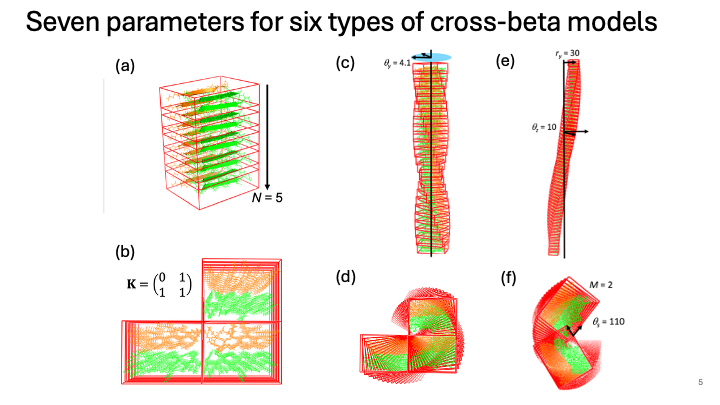

In [1]:
from IPython.display import Image
Image("images/Slide5.png")

<a id='sheet'></a>
(a) We use our optimised bilayer to assemble a **sheet** structure. We change the number of stacking units (parameter $N$) along the beta-sheet axis and visualise the structure. The output structure is built from stacked unit blocks. Ruturn to the [top](#top) to browse through other cross-beta structures.

## Edit your parameters here

In [2]:
Root_in = 'data_bilayers/'
Input_filename = 'F8_bilayer.pdb' #@param {type:"string"}
Input_num_peptides_per_sheet = 10 #@param {type:"integer"}
Num_residues_per_peptide = 8 #@param {type:"integer"}
Reference_segment = '2-8' #@param {type:"string"}
N = 10 #@param {type:"integer"}
Output_filename = 'F8_sheet.pdb' #@param {type:"string"}
Show_the_structure = True #@param {type:"boolean"}
#@markdown - Parameter $N$ is an integer repeating stacking along the vertical axis.

## Run this code to build your sheet structure

In [3]:
root = 'data_fibrils/'

from fibrilgen_local.builder import *

## Reset
pymol.cmd.delete('all')
pymol.cmd.reset()

## Load PDB
pymol.cmd.load(Root_in+Input_filename)

## Create a periodic unit
# INPUT: (peptide length, the number of peptides per sheet, start residue index, end residue index)
resi_start, resi_end = Reference_segment.split('-')
unit = create_sheet_unit(Num_residues_per_peptide,Input_num_peptides_per_sheet,int(resi_start),int(resi_end))

## Create a fibril object
fibril = create_fibril(unit)

## Build a plain sheet (num of units per sheet)
fibril.build_a_flat_sheet(N)

## Save the structure
pymol.cmd.save(root+Output_filename,'plain_sheet')

## Show the structure
if Show_the_structure:
  import py3Dmol
  with open(root+Output_filename) as ifile:
      system = "".join([x for x in ifile])
  view = py3Dmol.view(width=900, height=300)
  view.addModelsAsFrames(system)
  view.setStyle({"stick": {'color': 'spectrum'}})
  view.zoomTo()
  view.show()



3Dmol.js failed to load for some reason. Please check your browser console for error messages.

<a id='stacked_sheet'></a>
(b) We use our optimised bilayer to assemble a **stacked sheet** structure. We vary the number of stacking units in the sheet cross-section (parameter **K**; do not specify element 1 surrounded by element 0) and the number of stacking units (parameter $N$) along the beta-sheet axis. The output structure is built from stacked unit blocks. Ruturn to the [top](#top) to browse through other cross-beta structures.

## Edit your parameters here

In [4]:
Root_in = 'data_bilayers/'
Input_filename = 'F8_bilayer.pdb' #@param {type:"string"}
Input_num_peptides_per_sheet = 10 #@param {type:"integer"}
Num_residues_per_peptide = 8 #@param {type:"integer"}
Reference_segment = '2-8' #@param {type:"string"}
N = 10 #@param {type:"integer"}
K = '0_1_0,1_1_1' #@param {type:"string"}
Output_filename = 'F8_stacked_sheet.pdb' #@param {type:"string"}
Show_the_structure = True #@param {type:"boolean"}
#@markdown - Parameter $N$ is an integer repeating stacking along the vertical axis.
#@markdown - Parameter **K** is a binary matrix ("_" to seperate columns, "," to sperate rows) assigning w hether a 2 x 2 unit is presented.

## Run this code to build your stacked sheet structure

In [5]:
root = 'data_fibrils/'

from fibrilgen_local.builder import *

## Reset
pymol.cmd.delete('all')
pymol.cmd.reset()

## Load PDB
pymol.cmd.load(Root_in+Input_filename)

## Create a periodic unit
resi_start, resi_end = Reference_segment.split('-')
# INPUT: (peptide length, the number of peptides per sheet, start residue index, end residue index)
unit = create_sheet_unit(Num_residues_per_peptide,Input_num_peptides_per_sheet,int(resi_start),int(resi_end))

## Create a fibril object
fibril = create_fibril(unit)

## Build a stacked sheet (stacking pattern, num of units per sheet)
# Get parameters
lo_row = K.split(',')
matrix_K = []
for row in lo_row:
  cols = row.split('_')
  matrix_K += [[int(col) for col in cols]]
# Build the structure
fibril.build_a_stacked_sheet(matrix_K,N)

## Save the structure
pymol.cmd.save(root+Output_filename,'plain_sheet')

## Show the structure
if Show_the_structure:
  import py3Dmol
  with open(root+Output_filename) as ifile:
      system = "".join([x for x in ifile])
  view = py3Dmol.view(width=900, height=300)
  view.addModelsAsFrames(system)
  view.setStyle({"stick": {'color': 'spectrum'}})
  view.zoomTo()
  view.show()



3Dmol.js failed to load for some reason. Please check your browser console for error messages.

<a id='rod'></a>
(c) We use our optimised bilayer to assemble a **rod** structure. We change the twist chirality (the sign of parameter $\theta_y$), the initial tilt angle (parameter $\theta_z$), and the number of stacking units (parameter $N$) along the fibril axis. The output structure is built from stacked and twisted unit blocks.

We provide tips for parameter assignments:

- To relax the structure, try a smaller tilt angle $\theta_z$.

- The tilt angle is automatically refined to avoid steric clashes. The initial value affects the helical twist it converges to (or fails to converge to).

Ruturn to the [top](#top) to browse through other cross-beta structures.

## Edit your parameters here

In [6]:
Root_in = 'data_bilayers/'
Input_filename = 'F8_bilayer.pdb' #@param {type:"string"}
Input_num_peptides_per_sheet = 10 #@param {type:"integer"}
Num_residues_per_peptide = 8 #@param {type:"integer"}
Reference_segment = '2-8' #@param {type:"string"}
N = 50 #@param {type:"integer"}
theta_z = 5.0 #@param {type:"number"}
Sign_theta_y = 1 #@param {type:"integer"}
Output_filename = 'F8_rod.pdb' #@param {type:"string"}
Show_the_structure = True #@param {type:"boolean"}
#@markdown - Parameter $N$ is an integer repeating stacking along the vertical axis.
#@markdown - Parameter $\theta_z$ is the initial tilt angle.
#@markdown - Parameter "sign of $\theta_y$"" assigned to 1 for left-handed twist, and -1 for right handed twist.

## Run this code to build your rod structure

In [7]:
root = 'data_fibrils/'

from fibrilgen_local.builder import *

## Reset
pymol.cmd.delete('all')
pymol.cmd.reset()

## Load PDB
pymol.cmd.load(Root_in+Input_filename)

## Create a periodic unit
resi_start, resi_end = Reference_segment.split('-')
# INPUT: (peptide length, the number of peptides per sheet, start residue index, end residue index)
unit = create_sheet_unit(Num_residues_per_peptide,Input_num_peptides_per_sheet,int(resi_start),int(resi_end))

## Create a fibril object
fibril = create_fibril(unit)

## Build a rod (tilt angle, num of units per sheet, twist sign)
fibril.build_a_rod(theta_z,N,Sign_theta_y)

if fibril.write_output:
  ## Print the refined fibril dimension
  print ('\n')
  print ('##### Refined fibril structure #####')
  fibril.get_dimension()
  print ('#################################### \n')

  ## Save the structure
  pymol.cmd.save(root+Output_filename,'a_rod')

  ## Show the structure
  if Show_the_structure:
    import py3Dmol
    with open(root+Output_filename) as ifile:
        system = "".join([x for x in ifile])
    view = py3Dmol.view(width=900, height=300)
    view.addModelsAsFrames(system)
    view.setStyle({"stick": {'color': 'spectrum'}})
    view.zoomTo()
    view.show()





##### Refined fibril structure #####
Radius: 0.56 nm
Pitch length: 40.26 nm
Tilt angle: 5.00 degrees
Twist angle: 4.27 degrees
Period: 84.35 peptides
#################################### 



3Dmol.js failed to load for some reason. Please check your browser console for error messages.

<a id='stacked_rod'></a>
(d) We use our optimised bilayer to assemble a **stacked rod** structure. We change the number of stacking units on the fibril cross-section (parameter **K**; do not specify element 1 surrounded by element 0), the twist chirality (the sign of parameter $\theta_y$), the initial tilt angle (parameter $\theta_z$), and the number of stacking units (parameter $N$) along the fibril axis. The output structure is built from stacked and twisted unit blocks.

We provide tips for parameter assignments:

- To relax the structure, try a smaller tilt angle $\theta_z$.

- The tilt angle is automatically refined to avoid steric clashes. The initial value affects the helical twist it converges to (or fails to converge to).

Ruturn to the [top](#top) to browse through other cross-beta structures.

## Edit your parameters here

In [8]:
Root_in = 'data_bilayers/'
Input_filename = 'F8_bilayer.pdb' #@param {type:"string"}
Input_num_peptides_per_sheet = 10 #@param {type:"integer"}
Num_residues_per_peptide = 8 #@param {type:"integer"}
Reference_segment = '2-8' #@param {type:"string"}
N = 10 #@param {type:"integer"}
K = '0_1,1_1' #@param {type:"string"}
theta_z = 10.0 #@param {type:"number"}
Sign_theta_y = 1 #@param {type:"integer"}
Output_filename = 'F8_stacked_rod.pdb' #@param {type:"string"}
Show_the_structure = True #@param {type:"boolean"}
#@markdown - Parameter $N$ is an integer repeating stacking along the vertical axis.
#@markdown - Parameter **K** is a binary matrix ("_" to seperate columns, "," to sperate rows) assigning whether a 2 x 2 unit is presented.
#@markdown - Parameter $\theta_z$ is the initial tilt angle.
#@markdown - Parameter "sign of $\theta_y$"" assigned to 1 for left-handed twist, and -1 for right handed twist.

## Run this code to build your stacked rod structure

In [9]:
root = 'data_fibrils/'

from fibrilgen_local.builder import *

## Reset
pymol.cmd.delete('all')
pymol.cmd.reset()

## Load PDB
pymol.cmd.load(Root_in+Input_filename)

## Create a periodic unit
resi_start, resi_end = Reference_segment.split('-')
# INPUT: (peptide length, the number of peptides per sheet, start residue index, end residue index)
unit = create_sheet_unit(Num_residues_per_peptide,Input_num_peptides_per_sheet,int(resi_start),int(resi_end))

## Create a fibril object
fibril = create_fibril(unit)

## Build a stacked rod (tilt angle, stacking pattern, num of units per sheet, twist sign)
# Get parameters
lo_row = K.split(',')
matrix_K = []
for row in lo_row:
  cols = row.split('_')
  matrix_K += [[int(col) for col in cols]]
# Build the structure
fibril.build_a_stacked_rod(theta_z,matrix_K,N,Sign_theta_y)

if fibril.write_output:
  ## Print the refined fibril dimension
  print ('\n')
  print ('##### Refined fibril structure #####')
  fibril.get_dimension()
  print ('#################################### \n')

  ## Save the structure
  pymol.cmd.save(root+Output_filename,'s_rod')

  ## Show the structure
  if Show_the_structure:
    import py3Dmol
    with open(root+Output_filename) as ifile:
        system = "".join([x for x in ifile])
    view = py3Dmol.view(width=900, height=300)
    view.addModelsAsFrames(system)
    view.setStyle({"stick": {'color': 'spectrum'}})
    view.zoomTo()
    view.show()





##### Refined fibril structure #####
Radius: 2.25 nm
Pitch length: 80.08 nm
Tilt angle: 10.00 degrees
Twist angle: 2.12 degrees
Period: 169.71 peptides
#################################### 



3Dmol.js failed to load for some reason. Please check your browser console for error messages.

<a id='ribbon'></a>
(e) We use our optimised bilayer to assemble a **ribbon** structure. We change the twist chirality (the sign of parameter $\theta_y$), the initial tilt angle (parameter $\theta_z$), the initial radius of rotation (parameter $r_y$), and the number of stacking units (parameter $N$) along the fibril axis. The output structure is built from stacked and twisted unit blocks.

We provide tips for parameter assignments:

- To relax the structure, try a smaller tilt angle $\theta_z$.

- The tilt angle and radius are automatically refined to avoid steric clashes. The initial values affect the helical twist they converge to (or fail to converge to).

Ruturn to the [top](#top) to browse through other cross-beta structures.

## Edit your parameters here

In [10]:
Root_in = 'data_bilayers/'
Input_filename = 'F8_bilayer.pdb' #@param {type:"string"}
Input_num_peptides_per_sheet = 10 #@param {type:"integer"}
Num_residues_per_peptide = 8 #@param {type:"integer"}
Reference_segment = '2-8' #@param {type:"string"}
N = 50 #@param {type:"integer"}
theta_z = 30.0 #@param {type:"number"}
r_y = 60.0 #@param {type:"number"}
Sign_theta_y = -1 #@param {type:"integer"}
Output_filename = 'F8_ribbon.pdb' #@param {type:"string"}
Show_the_structure = True #@param {type:"boolean"}
#@markdown - Parameter $N$ is an integer repeating stacking along the vertical axis.
#@markdown - Parameter $\theta_z$ is the initial tilt angle.
#@markdown - Parameter $r_y$ is the initial radius of rotation.
#@markdown - Parameter "sign of $\theta_y$"" assigned to 1 for left-handed twist, and -1 for right handed twist.

## Run this code to build your ribbon structure

In [11]:
root = 'data_fibrils/'

from fibrilgen_local.builder import *

## Reset
pymol.cmd.delete('all')
pymol.cmd.reset()

## Load PDB
pymol.cmd.load(Root_in+Input_filename)

## Create a periodic unit
resi_start, resi_end = Reference_segment.split('-')
# INPUT: (peptide length, the number of peptides per sheet, start residue index, end residue index)
unit = create_sheet_unit(Num_residues_per_peptide,Input_num_peptides_per_sheet,int(resi_start),int(resi_end))

## Create a fibril object
fibril = create_fibril(unit)

## Build a ribbon (tilt angle, radius, num of units per sheet, twist sign)
fibril.build_a_ribbon(theta_z,r_y,N,Sign_theta_y)

if fibril.write_output:
  ## Print the refined fibril dimension
  print ('\n')
  print ('##### Refined fibril structure #####')
  fibril.get_dimension()
  print ('#################################### \n')

  ## Save the structure
  pymol.cmd.save(root+Output_filename,'a_ribbon')

  ## Show the structure
  if Show_the_structure:
    import py3Dmol
    with open(root+Output_filename) as ifile:
        system = "".join([x for x in ifile])
    view = py3Dmol.view(width=900, height=300)
    view.addModelsAsFrames(system)
    view.setStyle({"stick": {'color': 'spectrum'}})
    view.zoomTo()
    view.show()





##### Refined fibril structure #####
Radius: 7.70 nm
Pitch length: 260.54 nm
Tilt angle: 10.52 degrees
Twist angle: 0.65 degrees
Period: 553.06 peptides
#################################### 



3Dmol.js failed to load for some reason. Please check your browser console for error messages.

<a id='stacked_ribbon'></a>
(f) We use our optimised bilayer to assemble a **stacked ribbon** structure. We change the number of stacking units (parameter $M$) and the angle for stacking (parameter $\theta_s$) on the fibril cross-section; the twist chirality (the sign of parameter $\theta_y$); the initial tilt angle (parameter $\theta_z$); the initial radius of rotation (parameter $r_y$); and the number of stacking units (parameter $N$) along the fibril axis. The output structure is built from stacked and twisted unit blocks.

We provide tips for parameter assignments:

- Assign $\theta_s$ and $M$ such that $\theta_s\cdot M$ < 360 degrees.

- To relax the structure, try a smaller tilt angle $\theta_z$.

- The tilt angle and radius are automatically refined to avoid steric clashes and adjust the distance between neighbouring beta-sheets. The initial values affect the helical twist they converge to (or fail to converge to).

Ruturn to the [top](#top) to browse through other cross-beta structures.

## Edit your parameters here

In [12]:
Root_in = 'data_bilayers/'
Input_filename = 'F8_bilayer.pdb' #@param {type:"string"}
Input_num_peptides_per_sheet = 10 #@param {type:"integer"}
Num_residues_per_peptide = 8 #@param {type:"integer"}
Reference_segment = '2-8' #@param {type:"string"}
N = 20 #@param {type:"integer"}
theta_s = 90 #@param {type:"number"}
M = 2 #@param {type:"integer"}
theta_z = 10.0 #@param {type:"number"}
r_y = 30.0 #@param {type:"number"}
Sign_theta_y = 1 #@param {type:"integer"}
Output_filename = 'F8_stacked_ribbon.pdb' #@param {type:"string"}
Show_the_structure = True #@param {type:"boolean"}
#@markdown - Parameter $N$ is an integer repeating stacking along the vertical axis.
#@markdown - Parameter $\theta_s$ is angular displacement of units on the fibril cross-section.
#@markdown - Parameter $M$ is the number of stacking on the fibril cross-section.
#@markdown - Parameter $\theta_z$ is the initial tilt angle.
#@markdown - Parameter $r_y$ is the initial radius of rotation.
#@markdown - Parameter "sign of $\theta_y$"" assigned to 1 for left-handed twist, and -1 for right handed twist.

## Run this code to build your stacked ribbon structure

In [13]:
root = 'data_fibrils/'

from fibrilgen_local.builder import *

## Reset
pymol.cmd.delete('all')
pymol.cmd.reset()

## Load PDB
pymol.cmd.load(Root_in+Input_filename)

## Create a periodic unit
resi_start, resi_end = Reference_segment.split('-')
# INPUT: (peptide length, the number of peptides per sheet, start residue index, end residue index)
unit = create_sheet_unit(Num_residues_per_peptide,Input_num_peptides_per_sheet,int(resi_start),int(resi_end))

## Create a fibril object
fibril = create_fibril(unit)

## Build a stacked ribbon (tilt angle, radius, stacking angle, stacking number, num of units per sheet, twist sign)
fibril.build_a_stacked_ribbon(theta_z,r_y,theta_s,M,N,Sign_theta_y)

if fibril.write_output:
  # Print the refined fibril dimension
  print ('\n')
  print ('##### Refined fibril structure #####')
  fibril.get_dimension()
  print ('#################################### \n')

  ## Save the structure
  pymol.cmd.save(root+Output_filename,'s_ribbon')

  ## Show the structure
  if Show_the_structure:
    import py3Dmol
    with open(root+Output_filename) as ifile:
        system = "".join([x for x in ifile])
    view = py3Dmol.view(width=900, height=300)
    view.addModelsAsFrames(system)
    view.setStyle({"stick": {'color': 'spectrum'}})
    view.zoomTo()
    view.show()





##### Refined fibril structure #####
Radius: 2.70 nm
Pitch length: 108.90 nm
Tilt angle: 8.85 degrees
Twist angle: 1.57 degrees
Period: 230.02 peptides
#################################### 



3Dmol.js failed to load for some reason. Please check your browser console for error messages.